# All inports

In [1]:
# ---------------------------------------------------------------------------
# 1. Import modules & data
# ---------------------------------------------------------------------------
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from matplotlib.ticker import FuncFormatter

data_realo = pd.read_csv("Realo_MBF_datascience_SALE.csv") 

/tmp/ipykernel_41297/3609450301.py:10: DtypeWarning: Columns (21: detachment) have mixed types. Specify dtype option on import or set low_memory=False.
  data_realo = pd.read_csv("Realo_MBF_datascience_SALE.csv")


In [2]:
# ---------------------------------------------------------------------------
# 2. Data exploration
# ---------------------------------------------------------------------------

# Calculate the number of missing values per variable
missing = pd.DataFrame({
    "n_missing": data_realo.isna().sum(),
    "pct_missing": (data_realo.isna().mean() * 100).round(2),
}).sort_values("pct_missing", ascending=False)

print("\n" + "=" * 70)
print("MISSING VALUES PER VARIABLE (sorted, highest first)")
print("=" * 70)
print(missing.to_string())

print(f"\nVariables with no missing values:   {(missing['n_missing'] == 0).sum()}")
print(f"Variables with some missing values: {(missing['n_missing'] > 0).sum()}")
print(f"Variables completely empty (100%):  {(missing['pct_missing'] == 100).sum()}")

# Determine the datatype per variable
dtypes = pd.DataFrame({"dtype": data_realo.dtypes.astype(str)})

print("\n" + "=" * 70)
print("DATA TYPE PER VARIABLE (in file order)")
print("=" * 70)
print(dtypes.to_string())

print("\nNumber of variables per data type:")
print(dtypes["dtype"].value_counts().to_string())

# For now, we will not do anything about the missing values. The datatypes, 
# however, do need to be changed. 


MISSING VALUES PER VARIABLE (sorted, highest first)
                         n_missing  pct_missing
kLevel                      530955        98.26
renovationYear              524287        97.03
eLevel                      515568        95.42
hasSingleGlass              499660        92.47
hasSolarBoiler              488782        90.46
hasCentralHeating           441196        81.65
terraceArea                 379809        70.29
estimatedGardenArea         375661        69.52
hasSwimmingPool             360996        66.81
certificateDate             347557        64.32
floor                       346416        64.11
cadastralIncome             304651        56.38
detachment                  299795        55.48
hasDoubleGlass              202682        37.51
numberOfFloors              197253        36.51
numberOfSides               183058        33.88
buildingArea                163420        30.24
energyConsumption           158073        29.25
buildingCondition           155443 

In [3]:
# --- Convert variables to their appropriate datatypes -----------------------
# Empty cells are always treated as missing; they are never recoded (e.g. to 0 or False).

# Variables grouped by target datatype
admin_vars = ["addressId", "admin1Id", "admin1", "admin2Id", "admin2",
              "localityId", "locality", "subLocalityId", "subLocality",
              "districtId", "district", "postalCode", "niscode", "region"]
string_vars = ["marker"]
date_vars = ["firstListing", "lastListing", "certificateDate"]
category_vars = ["addressType", "housingType", "secondaryHousingType",
                 "detachment", "way", "heatingType", "floodProneLocation",
                 "buildingCondition"]
bool_vars = ["isPublicSale", "hasGarden", "isNewBuild", "hasSolarPanels",
             "hasSwimmingPool", "hasSingleGlass", "hasDoubleGlass",
             "hasCentralHeating", "hasSolarBoiler"]
int_vars = ["numberOfSides", "numberOfBedrooms", "numberOfBathrooms",
            "numberOfToilets", "numberOfFloors", "floor", "buildYear",
            "renovationYear"]
float_vars = ["lon", "lat", "price", "initialPrice", "habitableArea",
              "terraceArea", "buildingArea", "estimatedArea",
              "estimatedGardenArea", "energyConsumption", "eLevel", "kLevel",
              "distanceToNearestCenter", "busStopDistance",
              "trainStopDistance", "schoolDistance", "mScore",
              "greenCoverage", "cadastralIncome"]

# Step 1: Keep track of missing values before conversion
n_missing_before = data_realo.isna().sum()

# Step 2: convert each group
for var in admin_vars + string_vars:
    col = data_realo[var]
    # Numeric codes read as floats (e.g. 9000.0) are first made whole numbers,
    # so that the string becomes "9000" and not "9000.0"
    if pd.api.types.is_float_dtype(col):
        col = col.astype("Int64")
    data_realo[var] = col.astype("string").str.strip()

for var in date_vars:
    data_realo[var] = pd.to_datetime(data_realo[var], errors="coerce")

for var in category_vars:
    data_realo[var] = data_realo[var].astype("string").str.strip().astype("category")

bool_map = {"1": True, "0": False, "1.0": True, "0.0": False,
            "true": True, "false": False, "yes": True, "no": False}
for var in bool_vars:
    data_realo[var] = (data_realo[var].astype("string").str.strip().str.lower()
                       .map(bool_map).astype("boolean"))

for var in float_vars:
    data_realo[var] = pd.to_numeric(data_realo[var], errors="coerce").astype("Float64")

for var in int_vars:
    col = pd.to_numeric(data_realo[var], errors="coerce")
    non_whole = (col.notna() & (col % 1 != 0)).sum()
    if non_whole > 0:
        # Do not silently round: keep as Float64 and flag it
        print(f"WARNING: {var} has {non_whole} non-whole values; kept as Float64.")
        data_realo[var] = col.astype("Float64")
    else:
        data_realo[var] = col.astype("Int64")

# Step 3: check that the conversion did not create new missing values
# (a value that could not be converted, e.g. text in a numeric column, becomes <NA>)
n_missing_after = data_realo.isna().sum()
new_missing = (n_missing_after - n_missing_before)
new_missing = new_missing[new_missing > 0]

print("\n" + "=" * 70)
print("DATATYPE CONVERSION")
print("=" * 70)
if new_missing.empty:
    print("No values were lost in the conversion.")
else:
    print("Values that could not be converted and are now missing:")
    print(new_missing.to_string())

print("\nDatatypes after conversion:")
print(data_realo.dtypes.astype(str).to_string())

dtypes_after_conversion = pd.DataFrame({"dtype": data_realo.dtypes.astype(str)})
print("\nNumber of variables per data type:")
print(dtypes_after_conversion["dtype"].value_counts().to_string())


DATATYPE CONVERSION
No values were lost in the conversion.

Datatypes after conversion:
addressId                          string
admin1Id                           string
admin1                             string
admin2Id                           string
admin2                             string
localityId                         string
locality                           string
subLocalityId                      string
subLocality                        string
districtId                         string
district                           string
postalCode                         string
niscode                            string
region                             string
lon                               Float64
lat                               Float64
addressType                      category
firstListing               datetime64[us]
lastListing                datetime64[us]
housingType                      category
secondaryHousingType             category
detachment                   

In [4]:
data_realo = data_realo.drop([ 'way', 'hasGarden', 'isNewBuild',
       'buildYear', 'renovationYear', 'certificateDate',
       'eLevel', 'kLevel', 'heatingType', 'floodProneLocation',
       'numberOfBedrooms', 'numberOfBathrooms', 'numberOfToilets',
       'numberOfFloors', 'floor','buildingCondition', 'cadastralIncome', 'secondaryHousingType','hasSingleGlass',
       'hasDoubleGlass', 'hasSolarPanels', 'hasSwimmingPool',
       'hasCentralHeating', 'hasSolarBoiler','detachment', 'numberOfSides','hasCentralHeating', 'hasSolarBoiler','districtId'],axis=1)

In [5]:
# --- Observations per region, split by housing type ------------------------
# Number of observations per unique value of admin1 and admin2, split by
# housingType (i.e. APARTMENT vs HOUSE).
for region_var in ["admin1", "admin2"]:
    counts = pd.crosstab(
        data_realo[region_var].astype(object),
        data_realo["housingType"].astype(object),
        margins=True, margins_name="Total",
    )
    print("\n" + "=" * 70)
    print(f"NUMBER OF OBSERVATIONS PER {region_var.upper()} AND HOUSING TYPE")
    print("=" * 70)
    print(counts.to_string())


NUMBER OF OBSERVATIONS PER ADMIN1 AND HOUSING TYPE
housingType                   APARTMENT   HOUSE   Total
admin1                                                 
Oost-Vlaanderen                  103237  256532  359769
Région de Bruxelles-Capitale     140716   39857  180573
Total                            243953  296389  540342

NUMBER OF OBSERVATIONS PER ADMIN2 AND HOUSING TYPE
housingType         APARTMENT   HOUSE   Total
admin2                                       
Aalst                   18499   56648   75147
Brugge                      2       0       2
Bruxelles-Capitale     140716   39857  180573
Dendermonde             10399   33268   43667
Eeklo                    4695   16692   21387
Gent                    44576   81711  126287
Oudenaarde               7148   27860   35008
Sint-Niklaas            17918   40353   58271
Total                  243953  296389  540342


In [6]:
# --- Remove all observations with admin2 == "Brugge" ------------------------
# We remove these as Brugge is neither part of Oost-Vlaanderen nor Brussels 
data_realo = data_realo[data_realo["admin2"] != "Brugge"]

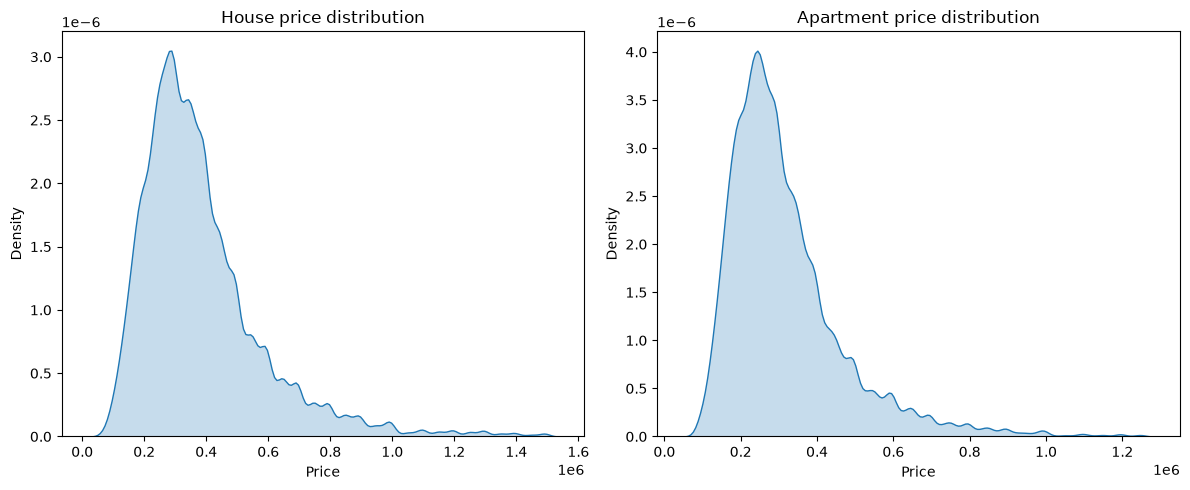

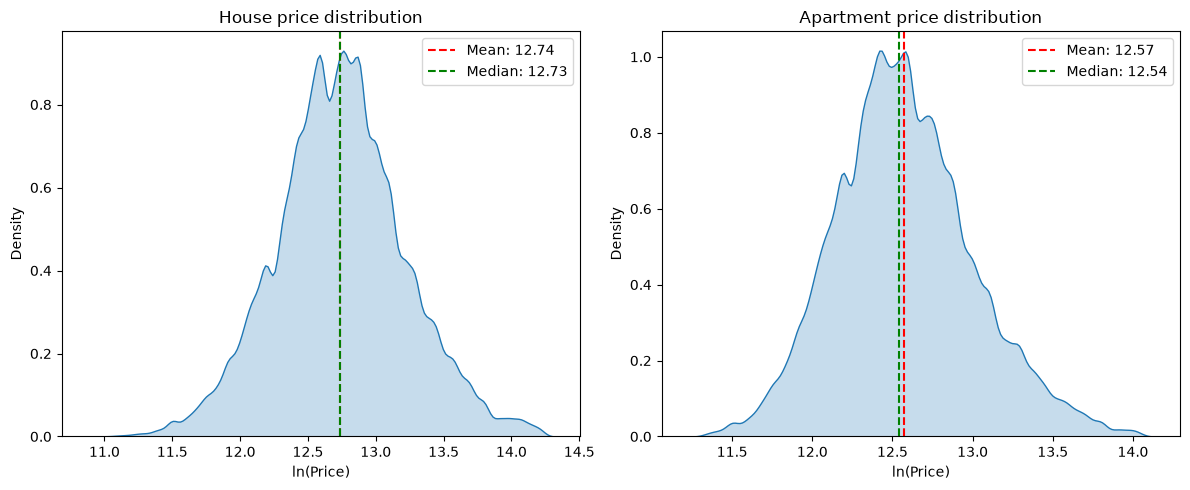

In [7]:
# ---------------------------------------------------------------------------
# 3. Plot price distribution
# ---------------------------------------------------------------------------

# Combine year and month into a single column
data_realo['firstListing year_month'] = data_realo['firstListing'].dt.to_period('M')
data_realo['lastListing year_month'] = data_realo['lastListing'].dt.to_period('M')

# Let's see what the distribution of 'Price' looks like for both apartments and houses
# Create a figure and two subplots (1 row, 2 columns)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Plot KDE for 'HOUSE' on the left subplot
sns.kdeplot(data=data_realo[data_realo['housingType'] == 'HOUSE'], x='price', ax=ax1, fill=True)
ax1.set_title('House price distribution')
ax1.set_xlabel('Price')
ax1.set_ylabel('Density')

# Plot KDE for 'APARTMENT' on the right subplot
sns.kdeplot(data=data_realo[data_realo['housingType'] == 'APARTMENT'], x='price', ax=ax2, fill=True)
ax2.set_title('Apartment price distribution')
ax2.set_xlabel('Price')
ax2.set_ylabel('Density')

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

# This data seems to be log-normally distributed. Let's do a log-transform and 
# plot again

data_realo["ln(price)"] = np.log(data_realo["price"]) 
data_realo["ln(initialPrice)"] = np.log(data_realo["initialPrice"]) 

# Create a figure and two subplots (1 row, 2 columns)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

# Left subplot: HOUSE 
house_data = data_realo[data_realo['housingType'] == 'HOUSE']['ln(price)']
sns.kdeplot(data=house_data, ax=ax1, fill=True)
ax1.set_title('House price distribution')
ax1.set_xlabel('ln(Price)')
ax1.set_ylabel('Density')

# Calculate mean and median for HOUSE
mean_house = house_data.mean()
median_house = house_data.median()

# Add vertical lines for mean and median
ax1.axvline(mean_house, color='red', linestyle='--', label=f'Mean: {mean_house:.2f}')
ax1.axvline(median_house, color='green', linestyle='--', label=f'Median: {median_house:.2f}')
ax1.legend()

# Right subplot: APARTMENT 
apartment_data = data_realo[data_realo['housingType'] == 'APARTMENT']['ln(price)']
sns.kdeplot(data=apartment_data, ax=ax2, fill=True)
ax2.set_title('Apartment price distribution')
ax2.set_xlabel('ln(Price)')
ax2.set_ylabel('Density')

# Calculate mean and median for APARTMENT
mean_apartment = apartment_data.mean()
median_apartment = apartment_data.median()

# Add vertical lines for mean and median
ax2.axvline(mean_apartment, color='red', linestyle='--', label=f'Mean: {mean_apartment:.2f}')
ax2.axvline(median_apartment, color='green', linestyle='--', label=f'Median: {median_apartment:.2f}')
ax2.legend()

# Adjust layout to prevent overlap
plt.tight_layout()
plt.show()

In [8]:
# ---------------------------------------------------------------------------
# 5. Plot evolution house prices, CPI, and gross income
# ---------------------------------------------------------------------------

data_CPI = pd.read_excel("CPI index.xlsx", sheet_name="CPI")
gross_income_data = pd.read_excel("evolution.xlsx",
                                  sheet_name= "NUTS3")

In [9]:
data_realo = data_realo[data_realo["estimatedArea"]!= np.nan]
data_realo["price/m2"] = data_realo["price"] / data_realo["estimatedArea"]
data_prices = data_realo.copy()


In [24]:
base_year = 2026

df = data_realo
df['pm2'] = df['price'] / df['habitableArea']
df['year_last'] = pd.to_datetime(df['lastListing'], errors='coerce').dt.year
df['year_first'] = pd.to_datetime(df['firstListing'], errors='coerce').dt.year

# mean price/m2 per housing type per year
level = df.groupby(['housingType', 'year_last'])['pm2'].mean().unstack('year_last')

# factor = 2026 level / level of that year
factor = level.div(level[base_year], axis=0).rdiv(1)   # = level[base_year] / level

# look up the factor for every listing
def get_factor(year_col):
    idx = pd.MultiIndex.from_arrays([df['housingType'], df[year_col]])
    return pd.Series(factor.stack().reindex(idx).to_numpy(), index=df.index)

f_last = get_factor('year_last')
f_first = get_factor('year_first')

df['inflation_factor'] = f_last
df['price_adj'] = df['price'] * f_last
df['initialPrice_adj'] = df['initialPrice'] * f_first
df['ln(price_adj)'] = df['ln(price)'] + np.log(f_last)
df['ln(initialPrice_adj)'] = df['ln(initialPrice)'] + np.log(f_first)
df['price/m2hab_adj'] = df['price_adj'] / df['habitableArea']

data_prices_adj = df

print(level.round(0))
print(f_last.isna().sum(), "rows without a factor")

year_last    2015.0  2016.0  2017.0  2018.0  2019.0  2020.0  2021.0  2022.0  \
housingType                                                                   
APARTMENT    2520.0  2641.0  2774.0  2854.0  3099.0  3200.0  3258.0  3332.0   
HOUSE        1679.0  1745.0  1771.0  1838.0  1882.0  2018.0  2094.0  2187.0   

year_last    2023.0  2024.0  2025.0  2026.0  
housingType                                  
APARTMENT    3406.0  3499.0  3506.0  3538.0  
HOUSE        2251.0  2273.0  2310.0  2360.0  
9763 rows without a factor


In [11]:
# --- Function: plot the evolution of house prices, CPI and gross income -----

def plot_index_evolution(data_prices=data_realo, data_CPI=data_CPI,
                         data_income=gross_income_data,
                         start_date="01/2015", end_date="08/2026", Lags=0):
    """
    Plot, per admin2 region, the indexed evolution (start_date = 100) of the
    median listing price of houses and apartments, the CPI and gross income.

    Parameters
    ----------
    data_prices : DataFrame with 'admin2', 'housingType',
                  'lastListing year_month' and 'price'.
    data_CPI    : DataFrame with 'Date' ("MM/YYYY" or datetime) and 'CPI index'.
    data_income : DataFrame with 'Abbreviated name' and one column per year.
    start_date  : base month and first month shown, "MM/YYYY".
    end_date    : last month shown, "MM/YYYY".
    Lags        : number of lags used for the price series ONLY. The price
                  in month t is the median of all listings in months
                  t-Lags, ..., t (pooled). Lags = 0 -> monthly median;
                  Lags = 11 -> 12 months of data (t-11 up to t).

    Raises
    ------
    ValueError if the price data of a region/housing type does not reach back
    to start_date - Lags, or if the CPI or gross income data do not contain
    the base period.
    """

    # --- Check and convert the arguments ------------------------------------
    if not isinstance(Lags, int) or Lags < 0:
        raise ValueError("Lags must be a non-negative integer.")
    start = pd.Period(pd.to_datetime(start_date, format="%m/%Y"), freq="M")
    end = pd.Period(pd.to_datetime(end_date, format="%m/%Y"), freq="M")
    if start > end:
        raise ValueError("start_date must be before end_date.")
    first_needed = start - Lags   # first month needed for the lagged series
    months = pd.period_range(start, end, freq="M")

    # Work on copies so that the original dataframes are not modified
    data_prices = data_prices.copy()
    data_CPI = data_CPI.copy()
    data_income = data_income.copy()

    # --- CPI: convert 'Date' ("MM/YYYY") to datetime --------------------------
    if not pd.api.types.is_datetime64_any_dtype(data_CPI["Date"]):
        data_CPI["Date"] = pd.to_datetime(data_CPI["Date"].astype(str),
                                          format="%m/%Y")
    cpi = data_CPI.set_index(data_CPI["Date"].dt.to_period("M"))["CPI index"]
    if start not in cpi.index:
        raise ValueError(f"The CPI data has no observation for {start_date} "
                         f"(it covers {cpi.index.min()} to {cpi.index.max()}).")
    cpi_index = cpi / cpi[start] * 100
    cpi_index = cpi_index[(cpi_index.index >= start) & (cpi_index.index <= end)]

    # --- Gross income: keep the relevant regions -----------------------------
    income_regions = ["Brussels Hoofdstedelijk Gewest", "Aalst", "Dendermonde",
                      "Eeklo", "Gent", "Oudenaarde", "Sint-Niklaas"]
    data_income = data_income[data_income["Abbreviated name"].isin(income_regions)]
    income_year_cols = [c for c in data_income.columns if str(c).isdigit()]
    income = data_income.set_index("Abbreviated name")[income_year_cols]
    income.columns = income.columns.astype(int)
    if start.year not in income.columns:
        raise ValueError(f"The gross income data has no observation for "
                         f"{start.year} (it covers {min(income.columns)} to "
                         f"{max(income.columns)}).")
    income_index = income.div(income[start.year], axis=0) * 100
    income_index = income_index.loc[:, (income_index.columns >= start.year)
                                       & (income_index.columns <= end.year)]

    # Link the 'admin2' names in the Realo data to the names in the income data
    region_map = {"Bruxelles-Capitale": "Brussels Hoofdstedelijk Gewest",
                  "Aalst": "Aalst", "Dendermonde": "Dendermonde",
                  "Eeklo": "Eeklo", "Gent": "Gent", "Oudenaarde": "Oudenaarde",
                  "Sint-Niklaas": "Sint-Niklaas"}

    # --- Prices: (lagged) median price index per region and housing type ----
    data_prices = data_prices.dropna(subset=["admin2", "housingType",
                                             "lastListing year_month", "price"])

    def lagged_median_index(region, housing_type):
        """Pooled median over months t-Lags ... t, indexed to start = 100."""
        sub = data_prices[(data_prices["admin2"] == region)
                          & (data_prices["housingType"] == housing_type)]
        listing_month = sub["lastListing year_month"]
        price = sub["price"].astype(float)

        # Error if the data does not reach back far enough
        if sub.empty or listing_month.min() > first_needed:
            first_available = "none" if sub.empty else listing_month.min()
            raise ValueError(
                f"Too few datapoints for {housing_type} in {region}: with "
                f"Lags = {Lags}, data from {first_needed} onwards is needed, "
                f"but the first observation is {first_available}.")

        median = pd.Series(
            [price[(listing_month >= t - Lags) & (listing_month <= t)].median()
             for t in months],
            index=months)

        if pd.isna(median[start]):
            raise ValueError(
                f"No {housing_type} listings for {region} in the window "
                f"{first_needed} to {start}; the base value cannot be computed.")
        return median / median[start] * 100

    # --- Plot: one panel per region ------------------------------------------
    window_label = "" if Lags == 0 else f" ({Lags + 1}-month window)"

    fig, axes = plt.subplots(2, 4, figsize=(20, 9), sharex=True, sharey=True)
    axes = axes.flatten()

    for ax, (region, income_name) in zip(axes, region_map.items()):

        # Median price index for houses and apartments
        for housing_type, label, color in [("HOUSE", "Median price houses", "tab:blue"),
                                           ("APARTMENT", "Median price apartments", "tab:orange")]:
            price_index = lagged_median_index(region, housing_type)
            ax.plot(price_index.index.to_timestamp(), price_index.values,
                    label=label + window_label, color=color, linewidth=1)

        # CPI index
        ax.plot(cpi_index.index.to_timestamp(), cpi_index.values,
                label="CPI", color="black", linewidth=1.5)

        # Gross income index, plotted in January of each year
        region_income = income_index.loc[income_name]
        income_dates = pd.to_datetime([f"{year}-01-01" for year in region_income.index])
        ax.plot(income_dates, region_income.values, label="Gross income",
                color="tab:green", marker="o", markersize=3, linewidth=1.5)

        ax.axhline(100, color="grey", linestyle=":", linewidth=1)
        ax.set_title(region)
        ax.tick_params(axis="x", rotation=45)

    # Show only the period start_date - end_date
    axes[0].set_xlim(start.to_timestamp(), end.to_timestamp(how="end"))

    # Hide the axes of the empty eighth panel (it is used for the legend below)
    for ax in axes[len(region_map):]:
        ax.axis("off")

    for ax in axes[::4]:
        ax.set_ylabel(f"Index ({start_date} = 100)")

    # One shared legend (taken from the first panel), placed inside the empty
    # eighth panel so that it cannot overlap with any of the region panels
    handles, labels = axes[0].get_legend_handles_labels()
    axes[-1].legend(handles, labels, loc="center", fontsize=11)

    fig.suptitle(f"Evolution of median listing prices, CPI and gross income "
                 f"(index, {start_date} = 100; gross income: {start.year} = 100; "
                 f"Lags = {Lags})",
                 fontsize=14)
    plt.tight_layout()
    plt.show()

    return fig


# Plot with the default settings (monthly medians, 01/2015 - 08/2026)
#plot_index_evolution(end_date="10/2026")

# Plot for period 01/2017-08/2026 with lags = 11s

In [12]:
data_prices['price/m2hab'] = data_prices['price'] / data_prices['habitableArea']

# Distance to center

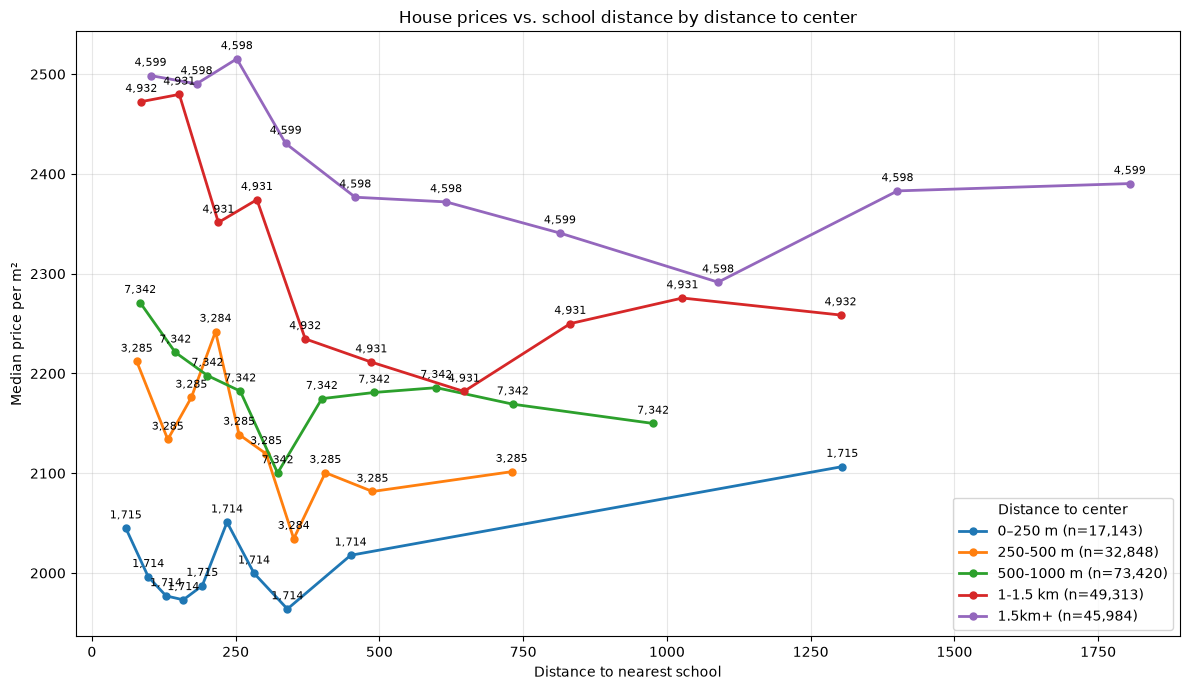

center_bin  school_distance   median_ppm  house_count
   0–250 m             59.0  2044.977166         1715
   0–250 m             98.0  1996.238566         1714
   0–250 m            129.0  1977.080964         1714
   0–250 m            159.0  1973.138719         1714
   0–250 m            192.0  1987.382828         1715
   0–250 m            235.0  2050.923657         1714
   0–250 m            282.0  1999.751466         1714
   0–250 m            340.0  1963.950144         1714
   0–250 m            450.0     2017.778         1714
   0–250 m           1305.0  2106.664329         1715
  1-1.5 km             86.0  2472.474415         4932
  1-1.5 km            152.0  2479.729519         4931
  1-1.5 km            220.0  2351.362612         4931
  1-1.5 km            287.0  2374.202462         4931
  1-1.5 km            371.0   2234.68527         4932
  1-1.5 km            486.0  2211.410068         4931
  1-1.5 km            647.0  2181.998163         4931
  1-1.5 km            832.0 

In [13]:
d = df.query("housingType == 'HOUSE'").copy()

d["ppm"] = pd.to_numeric(d["price/m2hab_adj"], errors="coerce")
d["center"] = pd.to_numeric(d["distanceToNearestCenter"], errors="coerce")
d["school"] = pd.to_numeric(d["schoolDistance"], errors="coerce")

d = d.dropna(subset=["ppm", "school", "center"])

# Fixed distance-to-center buckets
center_bins = [0, 250,500,1000,1500, float("inf")]
center_labels = ["0–250 m", "250-500 m", "500-1000 m", "1-1.5 km","1.5km+"]

d["center_bin"] = pd.cut(
    d["center"],
    bins=center_bins,
    labels=center_labels,
    right=False,
    include_lowest=True
)

d = d.dropna(subset=["center_bin"])

# Create 10 approximately equal-sized groups within each center bucket
n_points = 10
summaries = []

for label in center_labels:
    group = d[d["center_bin"] == label].copy()

    if group.empty:
        continue

    # Rank first to handle repeated school distances more robustly
    group["school_bin"] = pd.qcut(
        group["school"].rank(method="first"),
        q=min(n_points, len(group)),
        labels=False
    )

    summary_group = (
        group.groupby("school_bin")
        .agg(
            school_distance=("school", "median"),
            median_ppm=("ppm", "median"),
            house_count=("ppm", "size")
        )
        .reset_index()
    )

    summary_group["center_bin"] = label
    summaries.append(summary_group)

summary = pd.concat(summaries, ignore_index=True)

# Plot
fig, ax = plt.subplots(figsize=(12, 7))

for label in center_labels:
    subset = (
        summary[summary["center_bin"] == label]
        .sort_values("school_distance")
    )

    if subset.empty:
        continue

    ax.plot(
        subset["school_distance"],
        subset["median_ppm"],
        marker="o",
        markersize=5,
        linewidth=2,
        label=f"{label} (n={d[d['center_bin'] == label].shape[0]:,})"
    )

    # Show house count at each point
    for _, row in subset.iterrows():
        ax.annotate(
            f"{int(row['house_count']):,}",
            (row["school_distance"], row["median_ppm"]),
            xytext=(0, 7),
            textcoords="offset points",
            ha="center",
            fontsize=8
        )

ax.set_xlabel("Distance to nearest school")
ax.set_ylabel("Median price per m²")
ax.set_title("House prices vs. school distance by distance to center")
ax.grid(True, alpha=0.3)
ax.legend(title="Distance to center")
plt.tight_layout()
plt.show()

# Check the number of houses per plotted point
print(
    summary[["center_bin", "school_distance", "median_ppm", "house_count"]]
    .sort_values(["center_bin", "school_distance"])
    .to_string(index=False)
)

# School- en treinafstand is belangrijk 

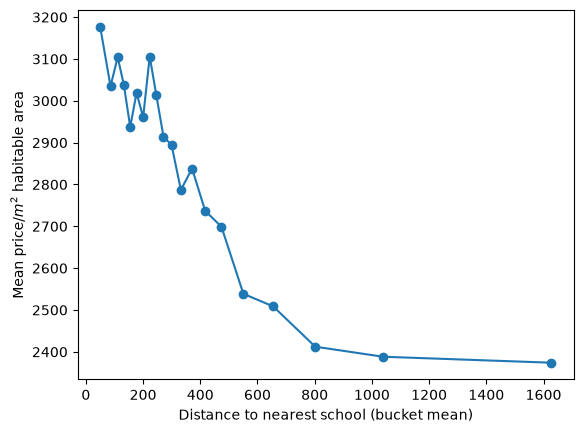

In [15]:
df1= df.dropna(subset=['schoolDistance', 'price/m2hab_adj'])

# 20 buckets with (roughly) the same number of rows each
df1 = df1.assign(bucket=pd.qcut(df['schoolDistance'], q=20, duplicates='drop'))

agg = df1.groupby('bucket', observed=True).agg(
    distance=('schoolDistance', 'mean'),
    price_per_sqm=('price/m2hab_adj', 'mean'),
    n=('price/m2hab_adj', 'size'),
)

plt.plot(agg['distance'], agg['price_per_sqm'], 'o-')
plt.xlabel('Distance to nearest school (bucket mean)')
plt.ylabel('Mean price/$m^2$ habitable area')
plt.show()

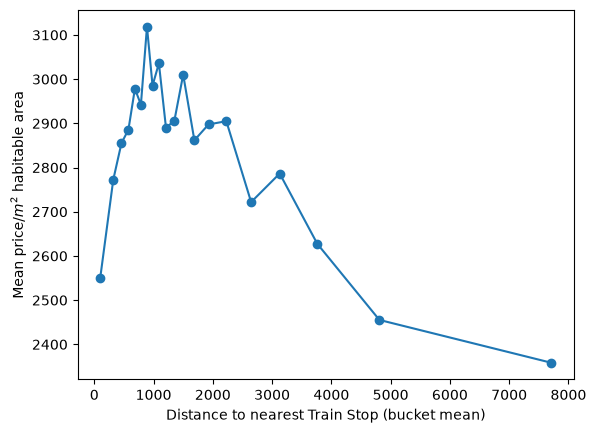

In [16]:
df1= df.dropna(subset=['trainStopDistance', 'price/m2hab_adj'])

# 20 buckets with (roughly) the same number of rows each
df1 = df1.assign(bucket=pd.qcut(df['trainStopDistance'], q=20, duplicates='drop'))

agg = df1.groupby('bucket', observed=True).agg(
    distance=('trainStopDistance', 'mean'),
    price_per_sqm=('price/m2hab_adj', 'mean'),
    n=('price/m2hab_adj', 'size'),
)

plt.plot(agg['distance'], agg['price_per_sqm'], 'o-')
plt.xlabel('Distance to nearest Train Stop (bucket mean)')
plt.ylabel('Mean price/$m^2$ habitable area')
plt.show()

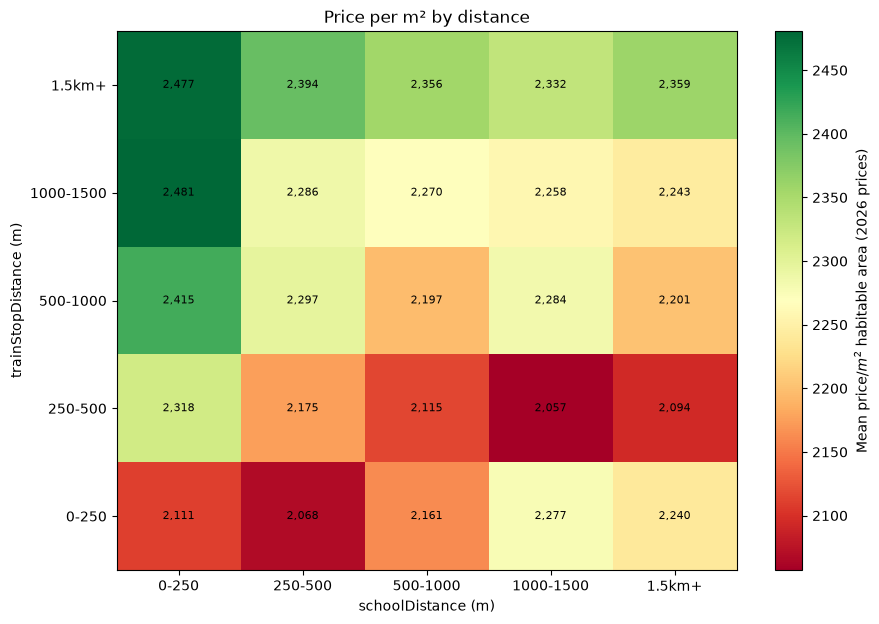

In [17]:
edges  = [0,250,500, 1000, 1500,np.inf]
labels = ['0-250','250-500', '500-1000', '1000-1500','1.5km+']

def distance_heatmap(data, xcol='schoolDistance', ycol='trainStopDistance',
                     zcol='price/m2hab_adj', admin1=None, admin2=None, locality=None,
                     admin2without=None, year_only=None, year_begin=None, year_end=None,
                     min_n=10, xedges=edges, yedges=edges, xlabels=labels, ylabels=labels,
                     cmap='RdYlGn', title=None):
    d = data
    if admin1 is not None:
        d = d[d['admin1'].to_numpy() == admin1]
    if admin2 is not None:
        d = d[d['admin2'].to_numpy() == admin2]
    if admin2without is not None:
        d = d[d['admin2'].to_numpy() != admin2without]
    if locality is not None:
        d = d[d['locality'].to_numpy() == locality]
    if year_only is not None:                       # exactly this year
        d = d[d['year_last'].to_numpy() == year_only]
    if year_begin is not None:                      # year_begin <= year < year_end
        d = d[d['year_last'].to_numpy() >= year_begin]
    if year_end is not None:
        d = d[d['year_last'].to_numpy() < year_end]

    # numeric only, no NaN / inf / negative distances
    d = d[[xcol, ycol, zcol]].apply(pd.to_numeric, errors='coerce')
    d = d.replace([np.inf, -np.inf], np.nan).dropna()
    d = d[(d[xcol] >= 0) & (d[ycol] >= 0)]
    if d.empty:
        print("No rows left after filtering"); return None, None

    nx, ny = len(xlabels), len(ylabels)
    # bin index per row: bins are [lower, upper), the last one is open-ended
    xi = np.digitize(d[xcol].to_numpy(), xedges[1:-1])
    yi = np.digitize(d[ycol].to_numpy(), yedges[1:-1])
    flat = yi * nx + xi

    s = np.bincount(flat, weights=d[zcol].to_numpy(), minlength=nx * ny).reshape(ny, nx)
    n = np.bincount(flat, minlength=nx * ny).reshape(ny, nx)
    mean = np.where(n >= min_n, s / np.maximum(n, 1), np.nan)   # hide cells with too few houses

    fig, ax = plt.subplots(figsize=(10, 7))
    cm = plt.get_cmap(cmap).copy()
    cm.set_bad('lightgrey')                                      # cells below min_n
    im = ax.imshow(np.ma.masked_invalid(mean), origin='lower', cmap=cm, aspect='auto')
    fig.colorbar(im, label='Mean price/$m^2$ habitable area (2026 prices)')
    ax.set_xticks(range(nx), xlabels)
    ax.set_yticks(range(ny), ylabels)
    ax.set_xlabel(f'{xcol} (m)')
    ax.set_ylabel(f'{ycol} (m)')
    ax.set_title(title or admin2 or locality or 'Price per m² by distance')

    # price and number of observations in each cell
    for i in range(ny):
        for j in range(nx):
            if n[i, j] >= min_n:
                ax.text(j, i, f"{mean[i, j]:,.0f}", #\n(n={n[i, j]}
                        ha='center', va='center', fontsize=8, color='black')
            else:
                ax.text(j, i, f"n={n[i, j]}", ha='center', va='center', fontsize=8, color='grey')

    plt.show()
    return (pd.DataFrame(mean, index=ylabels, columns=xlabels),
            pd.DataFrame(n, index=ylabels, columns=xlabels))

mean_tbl, n_tbl = distance_heatmap(df[df['housingType']=='HOUSE'],year_begin=2015, year_end=2020)                                   # whole dataset
# mean_tbl, n_tbl = distance_heatmap(df, admin2='Dendermonde')           # one arrondissement
# mean_tbl, n_tbl = distance_heatmap(df, year_begin=2015, year_end=2020) # 2023, 2024 and 2025

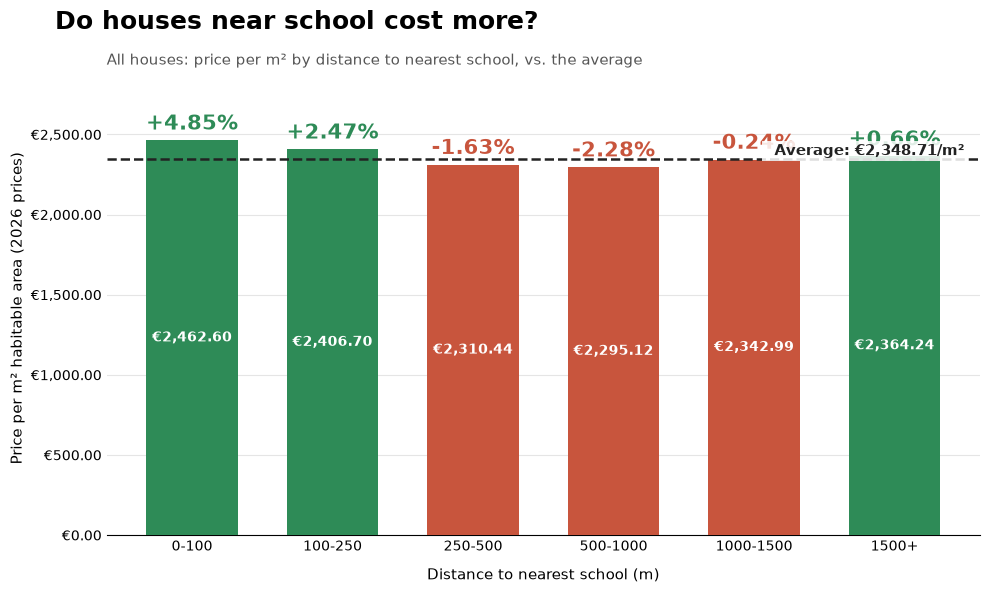

,mean_price,pct_vs_avg,n
0-100,2462.604197,0.048492,16154
100-250,2406.699391,0.024690,58554
250-500,2310.437534,-0.016295,66482
500-1000,2295.117455,-0.022818,51002
1000-1500,2342.992440,-0.002434,17384
1500+,2364.240290,0.006612,9132


In [25]:

edges  = [0.1,100,250, 500, 1000, 1500, np.inf]
labels = ['0-100','100-250', '250-500', '500-1000', '1000-1500', '1500+']

def school_distance_bar(data, xcol='schoolDistance', zcol='price/m2hab_adj',
                        admin1=None, admin2=None, locality=None, admin2without=None,
                        min_n=10, xedges=edges, xlabels=labels,
                        title=None, subtitle=None,
                        up_color='#2E8B57', down_color='#C8553D', avg_color='#222222'):
    d = data
    if admin2 is not None:
        d = d[d['admin2'].to_numpy() == admin2]
    if admin2without is not None:
        d = d[d['admin2'].to_numpy() != admin2without]
    if admin1 is not None:
        d = d[d['admin1'].to_numpy() == admin1]
    if locality is not None:
        d = d[d['locality'].to_numpy() == locality]
    d = d[[xcol, zcol]].dropna()

    nx = len(xlabels)
    xi = np.digitize(d[xcol].to_numpy(), xedges[1:-1])
    s = np.bincount(xi, weights=d[zcol].to_numpy(), minlength=nx)
    n = np.bincount(xi, minlength=nx)
    mean = np.where(n >= min_n, s / np.maximum(n, 1), np.nan)

    overall = d[zcol].mean()
    pct = mean / overall - 1                      # 4000 vs 3000 -> +0.33

    # ---- plot ----
    fig, ax = plt.subplots(figsize=(10, 6))
    fig.patch.set_facecolor('white')
    x = np.arange(nx)
    colors = [up_color if (p >= 0) else down_color for p in np.nan_to_num(pct)]
    bars = ax.bar(x, np.nan_to_num(mean), width=0.65, color=colors, zorder=3)

    # average line
    ax.axhline(overall, color=avg_color, lw=1.8, ls='--', zorder=4)
    ax.text(nx - 0.5, overall, f'  Average: €{overall:,.2f}/m²', va='bottom', ha='right',
            fontsize=11, fontweight='bold', color=avg_color, zorder=5,
            bbox=dict(facecolor='white', edgecolor='none', pad=2, alpha=0.85))

    # labels on bars
    top = np.nanmax(mean)
    for i, (m, p, cnt) in enumerate(zip(mean, pct, n)):
        if np.isnan(m):
            ax.text(i, overall * 0.04, f'n={cnt}\n(too few)', ha='center', va='bottom',
                    fontsize=9, color='#999999')
            continue
        ax.text(i, m + top * 0.015, f'{p:+.2%}', ha='center', va='bottom',
                fontsize=15, fontweight='bold', color=up_color if p >= 0 else down_color)
        ax.text(i, m / 2, f'€{m:,.2f}', ha='center', va='center',
                fontsize=10, color='white', fontweight='bold')

    ax.set_xticks(x)
    ax.set_xticklabels([f'{l}' for l, c in zip(xlabels, n)], fontsize=10)
    ax.set_xlabel('Distance to nearest school (m)', fontsize=11, labelpad=10)
    ax.set_ylabel('Price per m² habitable area (2026 prices)', fontsize=11)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'€{v:,.2f}'))
    ax.set_ylim(0, top * 1.15)

    # clean look
    for sp in ['top', 'right', 'left']:
        ax.spines[sp].set_visible(False)
    ax.tick_params(axis='y', length=0)
    ax.tick_params(axis='x', length=0)
    ax.grid(axis='y', color='#E5E5E5', zorder=0)

    main_title = title or 'Do houses near school cost more?'
    fig.suptitle(main_title, x=0.06, y=0.98, ha='left', fontsize=18, fontweight='bold')
    sub = subtitle or (locality or admin2 or admin1 or 'All houses')
    ax.set_title(f'{sub}: price per m² by distance to nearest school, vs. the average',
                 loc='left', fontsize=11, color='#555555', pad=12)

    plt.tight_layout()
    plt.show()
    return pd.DataFrame({'mean_price': mean, 'pct_vs_avg': pct, 'n': n}, index=xlabels)

tbl = school_distance_bar(df[df['housingType']=='HOUSE'],xcol='schoolDistance')
tbl

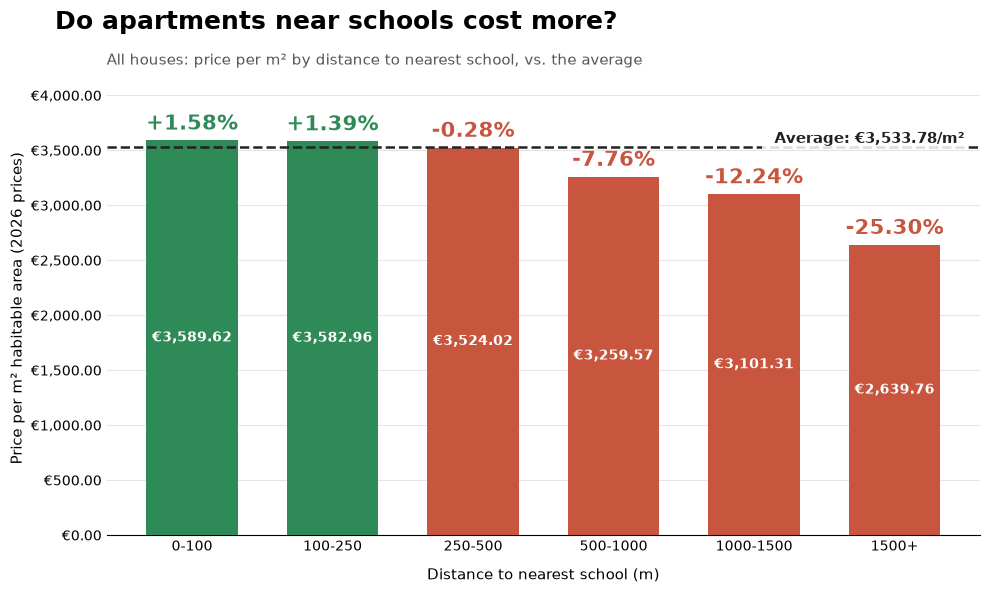

,mean_price,pct_vs_avg,n
0-100,3589.623378,0.015804,21616
100-250,3582.963946,0.013919,65462
250-500,3524.015821,-0.002762,49281
500-1000,3259.573531,-0.077595,11783
1000-1500,3101.305630,-0.122382,1232
1500+,2639.759718,-0.252992,204


In [28]:
tbl = school_distance_bar(df[df['housingType']=='APARTMENT'],xcol='schoolDistance', title='Do apartments near schools cost more?')
tbl

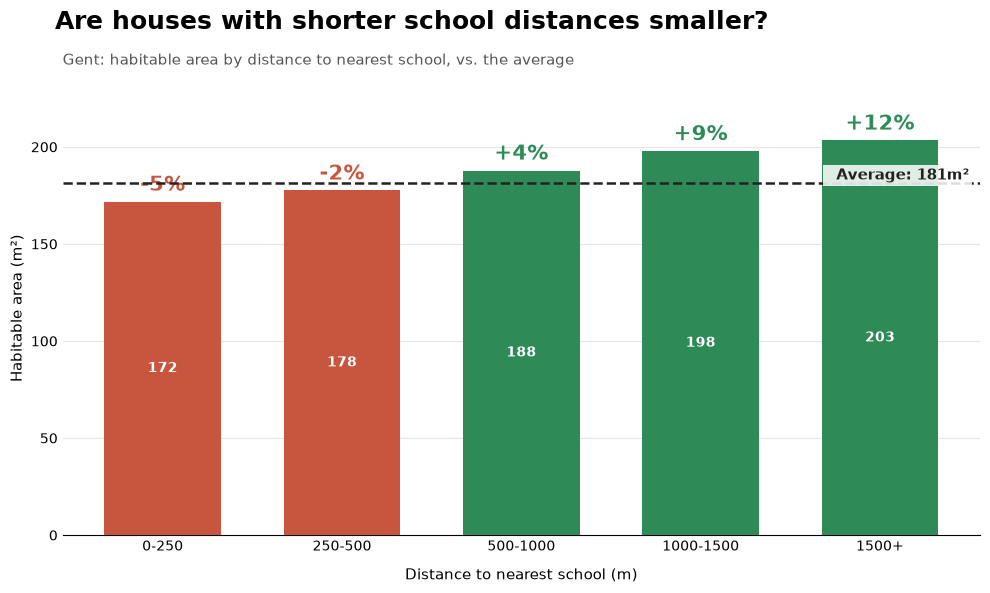

,mean_size,pct_vs_avg,n
0-250,171.786977,-0.052634,19120
250-500,177.573066,-0.020725,17710
500-1000,187.823662,0.035804,15544
1000-1500,197.857772,0.091140,5449
1500+,203.303443,0.121172,2643


In [33]:
edges  = [0.1,250, 500, 1000, 1500, np.inf]
labels = ['0-250', '250-500', '500-1000', '1000-1500', '1500+']

def school_distance_bar(data, xcol='schoolDistance', zcol='habitableArea',
                        admin1=None, admin2=None, locality=None, admin2without=None,
                        min_n=10, xedges=edges, xlabels=labels,
                        title=None, subtitle=None,
                        up_color='#2E8B57', down_color='#C8553D', avg_color='#222222'):
    d = data
    if admin2 is not None:
        d = d[d['admin2'].to_numpy() == admin2]
    if admin2without is not None:
        d = d[d['admin2'].to_numpy() != admin2without]
    if admin1 is not None:
        d = d[d['admin1'].to_numpy() == admin1]
    if locality is not None:
        d = d[d['locality'].to_numpy() == locality]
    d = d[[xcol, zcol]].dropna()

    nx = len(xlabels)
    xi = np.digitize(d[xcol].to_numpy(), xedges[1:-1])
    s = np.bincount(xi, weights=d[zcol].to_numpy(), minlength=nx)
    n = np.bincount(xi, minlength=nx)
    mean = np.where(n >= min_n, s / np.maximum(n, 1), np.nan)

    overall = d[zcol].mean()
    pct = mean / overall - 1                      # 4000 vs 3000 -> +0.33

    # ---- plot ----
    fig, ax = plt.subplots(figsize=(10, 6))
    fig.patch.set_facecolor('white')
    x = np.arange(nx)
    colors = [up_color if (p >= 0) else down_color for p in np.nan_to_num(pct)]
    bars = ax.bar(x, np.nan_to_num(mean), width=0.65, color=colors, zorder=3)

    # average line
    ax.axhline(overall, color=avg_color, lw=1.8, ls='--', zorder=4)
    ax.text(nx - 0.5, overall, f'  Average: {overall:,.0f}m²', va='bottom', ha='right',
            fontsize=11, fontweight='bold', color=avg_color, zorder=5,
            bbox=dict(facecolor='white', edgecolor='none', pad=2, alpha=0.85))

    # labels on bars
    top = np.nanmax(mean)
    for i, (m, p, cnt) in enumerate(zip(mean, pct, n)):
        if np.isnan(m):
            ax.text(i, overall * 0.04, f'n={cnt}\n(too few)', ha='center', va='bottom',
                    fontsize=9, color='#999999')
            continue
        ax.text(i, m + top * 0.015, f'{p:+.0%}', ha='center', va='bottom',
                fontsize=15, fontweight='bold', color=up_color if p >= 0 else down_color)
        ax.text(i, m / 2, f'{m:,.0f}', ha='center', va='center',
                fontsize=10, color='white', fontweight='bold')

    ax.set_xticks(x)
    ax.set_xticklabels([f'{l}' for l, c in zip(xlabels, n)], fontsize=10)
    ax.set_xlabel('Distance to nearest school (m)', fontsize=11, labelpad=10)
    ax.set_ylabel('Habitable area (m²)', fontsize=11)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda v, _: f'{v:,.0f}'))
    ax.set_ylim(0, top * 1.15)

    # clean look
    for sp in ['top', 'right', 'left']:
        ax.spines[sp].set_visible(False)
    ax.tick_params(axis='y', length=0)
    ax.tick_params(axis='x', length=0)
    ax.grid(axis='y', color='#E5E5E5', zorder=0)

    main_title = title or 'Are houses with shorter school distances smaller?'
    fig.suptitle(main_title, x=0.06, y=0.98, ha='left', fontsize=18, fontweight='bold')
    sub = subtitle or (locality or admin2 or admin1 or 'All houses')
    ax.set_title(f'{sub}: habitable area by distance to nearest school, vs. the average',
                 loc='left', fontsize=11, color='#555555', pad=12)

    plt.tight_layout()
    plt.show()
    return pd.DataFrame({'mean_size': mean, 'pct_vs_avg': pct, 'n': n}, index=xlabels)

tbl = school_distance_bar(df[df['housingType'] == 'HOUSE'],admin2='Gent')
tbl

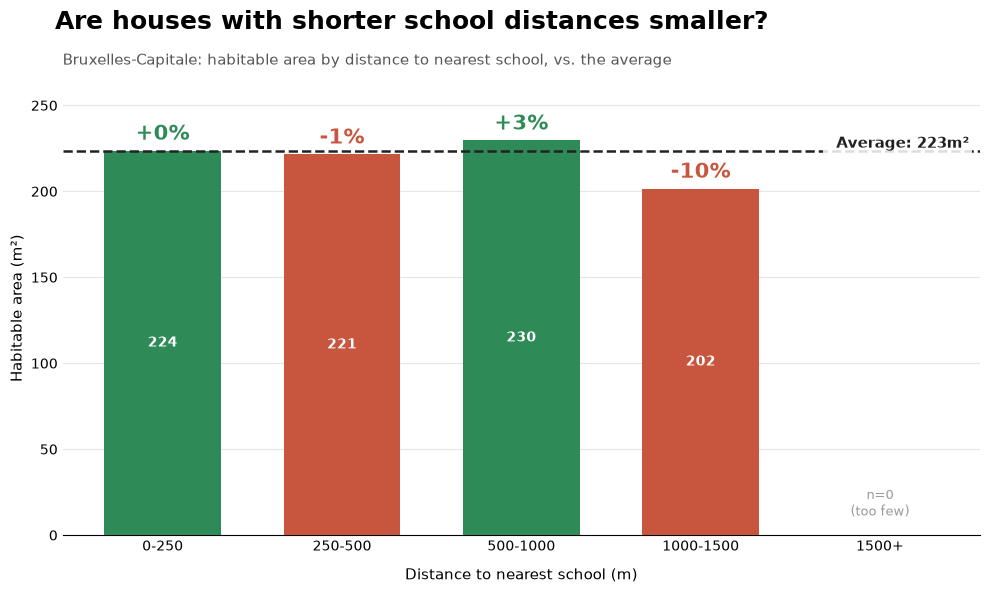

,mean_size,pct_vs_avg,n
0-250,223.665355,0.001875,21088
250-500,221.475738,-0.007933,8099
500-1000,229.575000,0.028346,920
1000-1500,201.571429,-0.097092,14
1500+,NaN,NaN,0


In [35]:
tbl = school_distance_bar(df[df['housingType'] == 'HOUSE'],admin2='Bruxelles-Capitale')
tbl

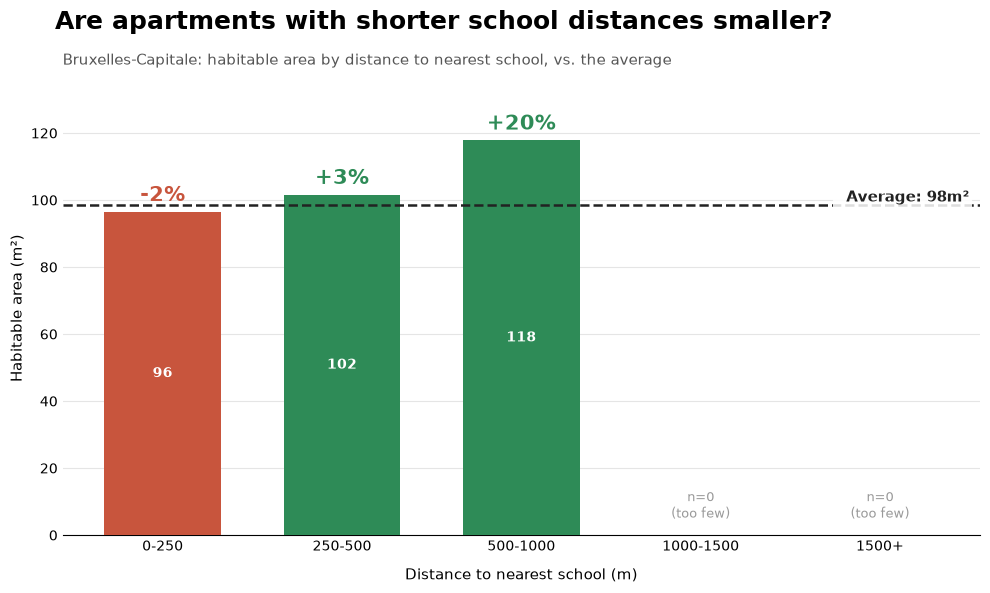

In [37]:
tbl = school_distance_bar(df[df['housingType'] == 'APARTMENT'], title='Are apartments with shorter school distances smaller?',admin2='Bruxelles-Capitale')


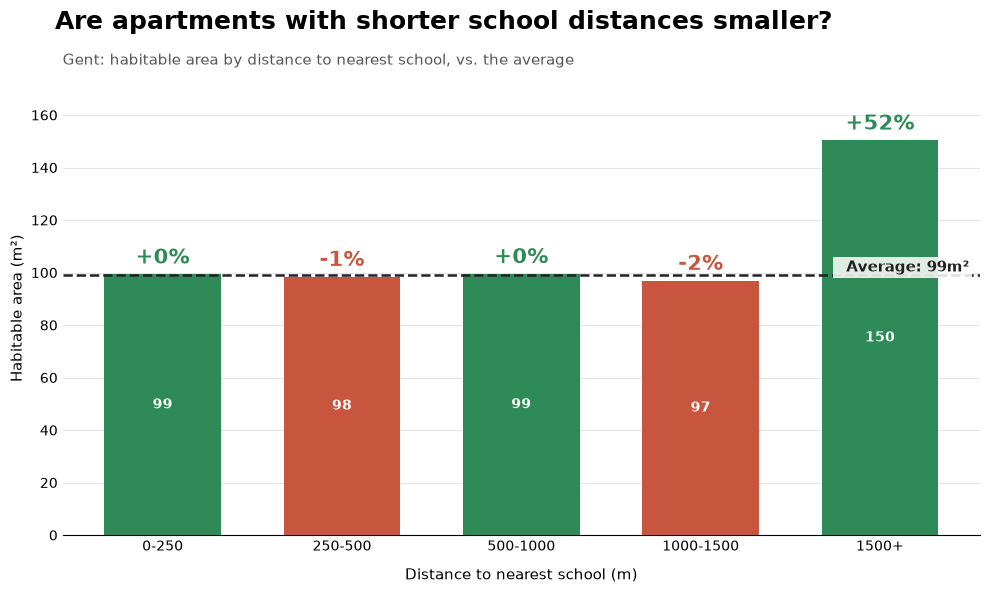

,mean_size,pct_vs_avg,n
0-250,99.278929,0.002724,14570
250-500,98.380584,-0.006349,9940
500-1000,99.428208,0.004232,4318
1000-1500,96.884021,-0.021464,388
1500+,150.307692,0.518118,26


In [36]:
tbl = school_distance_bar(df[df['housingType'] == 'APARTMENT'], title='Are apartments with shorter school distances smaller?',admin2='Gent')
tbl

mScore en distance To nearest center izjn verschillend 
-> dure huizen hebben hoge mscore maar zijn niet perse in het centrum 
-> liever goede nabijheid dan drukte? 

# BRUSSELS MAP

In [ ]:
from dotenv import load_dotenv
import os



In [ ]:
OPENAI_API_KEY='cb1_4r9c_1_6c4137313fd9cf4b83bc4b44'

load_dotenv()
key = os.getenv("OPENAI_API_KEY")

In [38]:
# pip install folium branca pyproj scipy
import re, numpy as np, pandas as pd, folium
import branca.colormap as cm
from pyproj import Transformer
from scipy.spatial import cKDTree

ZCOL   = 'price/m2hab_adj'
EDGES  = [ 250, 500, 1000, 1500]
LABELS = ['0-250', '250-500', '500-1000', '1000-1500']
BXL_BBOX = (4.24, 50.76, 4.50, 50.92)          # west, south, east, north

NR     = len(EDGES)          # <- add this line (number of rings = 4)


# ---------- 1. stations from your csv ----------
def load_stations(path='stations_bxl.csv'):
    rows = []
    with open(path, encoding='utf-8-sig') as f:
        for line in f:
            m = re.search(r'coordinates\W+\[\s*([-\d.]+)\s*,\s*([-\d.]+)\s*\]', line)
            if m:
                parts = line.split(';')
                rows.append({'name': parts[1].strip('"'),
                             'lon': float(m.group(1)), 'lat': float(m.group(2))})
    return pd.DataFrame(rows).drop_duplicates(['lon', 'lat']).reset_index(drop=True)

# ---------- 2. houses from df['marker'] ----------
def prepare_houses(df, zcol=ZCOL, bbox=BXL_BBOX):
    d = df.copy()
    ll = d['marker'].astype(str).str.extract(r'POINT\s*\(\s*([-\d.eE+]+)\s+([-\d.eE+]+)\s*\)')
    d['lon'] = pd.to_numeric(ll[0]); d['lat'] = pd.to_numeric(ll[1])
    d = d.dropna(subset=['lon', 'lat', zcol])
    w, s, e, n = bbox
    return d[d['lon'].between(w, e) & d['lat'].between(s, n)]

# ---------- 3. distance to nearest station + ring ----------
def assign_rings(houses, stations):
    tr = Transformer.from_crs(4326, 31370, always_xy=True)      # Belgian Lambert 72 (metres)
    hx, hy = tr.transform(houses['lon'].values, houses['lat'].values)
    sx, sy = tr.transform(stations['lon'].values, stations['lat'].values)
    dist, idx = cKDTree(np.c_[sx, sy]).query(np.c_[hx, hy])
    h = houses.copy()
    h['station_idx'] = idx
    h['station_dist'] = dist
    h['ring'] = np.digitize(dist, EDGES)                        # 0..4 = rings, 5 = outside 1500 m
    return h

# ---------- 4. map ----------
def station_ring_map(
    h,
    stations,
    zcol=ZCOL,
    min_n=3,
    per_station=True,
    opacity=0.4
):
    # Only houses within 1500 m of their nearest station
    inside = h[h['ring'] < NR].copy()

    # Average price within the full 1500 m area of each station
    if per_station:
        circle_avg = inside.groupby('station_idx')[zcol].mean()
        inside['ref'] = inside['station_idx'].map(circle_avg)
    else:
        overall_circle_avg = inside[zcol].mean()
        inside['ref'] = overall_circle_avg

    # Percentage difference from the 1500 m reference average
    inside['pct'] = (inside[zcol] / inside['ref'] - 1) * 100

    # Mean price and sample size for every station and ring
    st_ring = inside.groupby(['station_idx', 'ring']).agg(
        mean_price=(zcol, 'mean'),
        n=(zcol, 'size'),
        pct=('pct', 'mean')
    )

    # Ring mean compared with the full 1500 m average
    if per_station:
        st_ring['ref'] = (
            circle_avg.reindex(
                st_ring.index.get_level_values('station_idx')
            ).to_numpy()
        )
        st_ring['pct'] = (
            st_ring['mean_price'] / st_ring['ref'] - 1
        ) * 100
    else:
        st_ring['ref'] = overall_circle_avg
        st_ring['pct'] = (
            st_ring['mean_price'] / overall_circle_avg - 1
        ) * 100

    # Exclude rings with too few houses
    valid = st_ring[st_ring['n'] >= min_n].copy()

    if valid.empty:
        raise ValueError(
            "No station/ring combinations have enough houses. "
            "Try reducing min_n."
        )

    # Symmetric color scale centered on 0%
    lim = max(
        float(np.nanpercentile(valid['pct'].abs(), 95)),
        1.0
    )

    cmap = cm.LinearColormap(
        ['#D7191C', '#FFDD57', '#1A9641'],      # red (cheaper) -> yellow (average) -> green (more expensive)
        vmin=-lim,
        vmax=lim,
        caption=(
            'Price per m² vs. average price within the same '
            'station’s 1500 m area (%) · red = cheaper, green = more expensive'
        )
    )
        

    m = folium.Map(
        location=[50.835, 4.36],
        zoom_start=12,
        tiles='OpenStreetMap',
        control_scale=True
    )

    rings_layer = folium.FeatureGroup(
        name='Station rings',
        show=True
    ).add_to(m)

    # Draw larger rings first so smaller rings remain visible
    for ring in reversed(range(NR)):
        for i, s in stations.iterrows():

            if (i, ring) not in valid.index:
                continue

            r = valid.loc[(i, ring)]

            mean = float(r['mean_price'])
            pct = float(r['pct'])
            n = int(r['n'])
            ref = float(r['ref'])

            color = cmap(float(np.clip(pct, -lim, lim)))

            if not isinstance(color, str) or not color.startswith('#'):
                color = '#F7F7F7'

            folium.Circle(
                location=(s['lat'], s['lon']),
                radius=EDGES[ring],
                color='white',
                weight=0.6,
                fill=True,
                fill_color=color,
                fill_opacity=opacity,
                tooltip=(
                    f"{s['name']} · {LABELS[ring]} m · "
                    f"{pct:+.1f}% vs 1500 m average · "
                    f"€{mean:,.0f}/m² vs €{ref:,.0f}/m² · "
                    f"n={n}"
                )
            ).add_to(rings_layer)

    # Station markers
    for _, s in stations.iterrows():
        folium.CircleMarker(
            location=(s['lat'], s['lon']),
            radius=5,
            color='black',
            weight=1.5,
            fill=True,
            fill_color='white',
            fill_opacity=1,
            tooltip=s['name']
        ).add_to(m)

    cmap.add_to(m)
    folium.LayerControl(collapsed=False).add_to(m)

    # City-wide summary table
    table = inside.groupby('ring').agg(
        mean_price=(zcol, 'mean'),
        n=(zcol, 'size')
    )

    if per_station:
        # Average the station-specific ring percentages, giving
        # each station/ring combination equal weight.
        summary = valid.groupby(level='ring')['pct'].mean()
        table['pct_vs_circle'] = summary.reindex(table.index)
    else:
        table['pct_vs_circle'] = (
            table['mean_price'] / overall_circle_avg - 1
        ) * 100

    table.index = [LABELS[int(r)] for r in table.index]

    return m, table, st_ring


In [39]:
HUB_PATTERNS = HUBS = ['Brussel-Noord', 'Brussel-Centraal', 'Brussel-Zuid']      # Brussel-Zuid

def filter_stations(h, stations, min_circle=100, min_inner=20,
                    hub_patterns=HUB_PATTERNS, hub_radius=500):
    """
    Keep Noord/Centraal/Zuid always. Drop other stations that are
      - within hub_radius metres of one of those three hubs, or
      - below min_circle houses within 1500 m, or
      - below min_inner houses within 0-250 m.
    """
    inside   = h[h['ring'] < NR]
    n_circle = inside.groupby('station_idx').size().reindex(stations.index, fill_value=0)
    n_inner  = inside[inside['ring'] == 0].groupby('station_idx').size().reindex(stations.index, fill_value=0)

    # --- find the hubs by name ---
    names  = stations['name'].astype(str)
    is_hub = pd.Series(False, index=stations.index)
    for p in hub_patterns:
        is_hub |= names.str.contains(p, case=False, regex=True)
    print('Protected hubs:', list(names[is_hub]))
    if is_hub.sum() != len(hub_patterns):
        print(f'WARNING: expected {len(hub_patterns)} hubs, matched {is_hub.sum()}. '
              'Check the names above and adjust hub_patterns.')

    # --- distance of every station to its nearest hub (metres, Belgian Lambert 72) ---
    tr = Transformer.from_crs(4326, 31370, always_xy=True)
    sx, sy = tr.transform(stations['lon'].values, stations['lat'].values)
    pts = np.c_[sx, sy]
    d_hub = np.full(len(stations), np.inf)
    if is_hub.any():
        d_hub, _ = cKDTree(pts[is_hub.values]).query(pts)
    near_hub = (d_hub <= hub_radius) & ~is_hub.values

    enough = ((n_circle >= min_circle) & (n_inner >= min_inner)).values
    keep   = is_hub.values | (enough & ~near_hub)

    reason = np.select(
        [is_hub.values, near_hub, (n_circle < min_circle).values, (n_inner < min_inner).values],
        ['hub (always kept)', f'within {hub_radius} m of a hub',
         f'<{min_circle} houses in 1500 m', f'<{min_inner} houses in 0-250 m'],
        default='kept')

    report = stations.assign(n_1500=n_circle, n_0_250=n_inner,
                             dist_to_hub_m=np.round(d_hub), kept=keep, reason=reason)

    # Renumber survivors 0..k-1 so station_idx still matches stations.iterrows()
    keep_s  = pd.Series(keep, index=stations.index)
    new_idx = pd.Series(np.arange(keep.sum()), index=stations.index[keep_s])
    stations_f = stations[keep_s].reset_index(drop=True)
    h_f = h[h['station_idx'].isin(new_idx.index)].copy()
    h_f['station_idx'] = h_f['station_idx'].map(new_idx).astype(int)
    return h_f, stations_f, report

In [40]:
def station_pct_table(st_ring, stations, min_n=3, parameter='€/m²', sort_by='0-250 m'):
    ring_cols = [f'{LABELS[r]} m' for r in range(NR)]
    ref_col, n_col = '1500 m avg ' + parameter, 'n houses (1500 m)'

    ok  = st_ring[st_ring['n'] >= min_n]                       # same filter as the map
    pct = ok['pct'].unstack('ring').reindex(columns=range(NR)); pct.columns = ring_cols
    n   = ok['n'].unstack('ring').reindex(columns=range(NR));   n.columns   = ring_cols

    t = pct.copy()
    t['avg of rings'] = t.mean(axis=1)                         # per-station mean over its rings
    n_total = st_ring['n'].groupby(level='station_idx').sum().reindex(t.index)   # all houses within 1500 m
    t.insert(0, ref_col, st_ring['ref'].groupby(level='station_idx').first().reindex(t.index))
    t.insert(1, n_col, n_total)

    # simple average: every station counts the same
    simple = t.mean()
    simple[n_col] = n_total.sum()

    # weighted average: every house counts the same
    weighted = pd.Series(index=t.columns, dtype=float)
    weighted[ring_cols]      = ((pct * n).sum() / n.sum()).values   # per ring, weight = houses in that ring
    weighted['avg of rings'] = (pct * n).sum().sum() / n.sum().sum()   # ~0 by construction
    weighted[ref_col]        = np.average(t[ref_col], weights=n_total)
    weighted[n_col]          = n_total.sum()

    t = t.sort_values(sort_by, ascending=False)
    t.index = stations['name'].reindex(t.index).values
    t.index.name = 'station'
    t.loc['AVERAGE (all stations, equal weight)'] = simple
    t.loc['WEIGHTED AVERAGE (by houses)']         = weighted
    return t

In [41]:
def show_table(station_table, parameter='€/m²'):
    ref_col, n_col = '1500 m avg ' + parameter, 'n houses (1500 m)'
    pct_cols = [c for c in station_table.columns if c not in (ref_col, n_col)]
    return (station_table.style
            .format({**{c: '{:+.1f}%' for c in pct_cols},
                     ref_col: '€{:,.2f}', n_col: '{:,.2f}'}, na_rep='–'))

In [42]:
stations = load_stations('stations_bxl_all.csv')
houses   = prepare_houses(df[df['housingType']=='HOUSE'],zcol='price/m2hab_adj')
h        = assign_rings(houses, stations)

h, stations, report = filter_stations(h, stations, min_circle=100, min_inner=20)
print(len(stations), 'stations kept,', (~report['kept']).sum(), 'removed')
display(report[~report['kept']].sort_values('n_1500'))   # which stations were dropped and why

m, table, st_ring = station_ring_map(h, stations, per_station=True,zcol='price/m2hab_adj')
m.save('brussels_station_rings_FINAL_HOUSES.html')
display(table)
m

Protected hubs: ['Brussel-Zuid', 'Brussel-Noord', 'Brussel-Centraal']
23 stations kept, 10 removed


,name,lon,lat,n_1500,n_0_250,dist_to_hub_m,kept,reason
20,Vorst-Zuid,4.310348,50.810073,60,0,3387.0,False,<100 houses in 1500 m
12,Boondaal,4.393614,50.801952,193,17,5478.0,False,<20 houses in 0-250 m
14,Brussel-Luxemburg,4.373972,50.838838,275,8,1410.0,False,<20 houses in 0-250 m
21,Haren,4.420031,50.888871,295,18,5265.0,False,<20 houses in 0-250 m
25,Brussel-Congres,4.362220,50.851780,332,7,816.0,False,<20 houses in 0-250 m
8,Bosvoorde,4.408270,50.794558,442,14,6712.0,False,<20 houses in 0-250 m
19,Moensberg,4.333527,50.779471,507,17,6269.0,False,<20 houses in 0-250 m
27,Schaarbeek,4.378432,50.878693,788,5,2444.0,False,<20 houses in 0-250 m
1,Brussel-Schuman,4.380024,50.842849,802,18,1661.0,False,<20 houses in 0-250 m
13,Sint-Agatha-Berchem,4.290747,50.873034,910,7,5183.0,False,<20 houses in 0-250 m


,mean_price,n,pct_vs_circle
0-250,3029.919607,1036,-2.652425
250-500,2897.234238,3882,-3.122209
500-1000,2987.27011,8151,0.195139
1000-1500,3163.929787,4970,3.077147


In [45]:
stations = load_stations('stations_bxl_all.csv')
houses   = prepare_houses(df[df['housingType']=='HOUSE'],zcol='price/m2hab_adj')
h        = assign_rings(houses, stations)

h, stations, report = filter_stations(h, stations, min_circle=100, min_inner=20)
print(len(stations), 'stations kept,', (~report['kept']).sum(), 'removed')
display(report[~report['kept']].sort_values('n_1500'))   # which stations were dropped and why

m, table, st_ring = station_ring_map(h, stations, per_station=True,zcol='price/m2hab_adj')
m.save('brussels_station_rings_FINAL_HOUSES.html')
station_table = station_pct_table(st_ring, stations, min_n=3)    # use the same min_n as the map

show_table(station_table)

Protected hubs: ['Brussel-Zuid', 'Brussel-Noord', 'Brussel-Centraal']
23 stations kept, 10 removed


,name,lon,lat,n_1500,n_0_250,dist_to_hub_m,kept,reason
20,Vorst-Zuid,4.310348,50.810073,60,0,3387.0,False,<100 houses in 1500 m
12,Boondaal,4.393614,50.801952,193,17,5478.0,False,<20 houses in 0-250 m
14,Brussel-Luxemburg,4.373972,50.838838,275,8,1410.0,False,<20 houses in 0-250 m
21,Haren,4.420031,50.888871,295,18,5265.0,False,<20 houses in 0-250 m
25,Brussel-Congres,4.362220,50.851780,332,7,816.0,False,<20 houses in 0-250 m
8,Bosvoorde,4.408270,50.794558,442,14,6712.0,False,<20 houses in 0-250 m
19,Moensberg,4.333527,50.779471,507,17,6269.0,False,<20 houses in 0-250 m
27,Schaarbeek,4.378432,50.878693,788,5,2444.0,False,<20 houses in 0-250 m
1,Brussel-Schuman,4.380024,50.842849,802,18,1661.0,False,<20 houses in 0-250 m
13,Sint-Agatha-Berchem,4.290747,50.873034,910,7,5183.0,False,<20 houses in 0-250 m


,1500 m avg €/m²,n houses (1500 m),0-250 m,250-500 m,500-1000 m,1000-1500 m,avg of rings
station,,,,,,,
Brussel-Zuid,"€2,625.56","1,369.00",+16.8%,-14.8%,-5.0%,+11.3%,+2.1%
Etterbeek,"€3,498.37",512.00,+14.6%,-0.4%,-4.4%,+8.0%,+4.5%
Brussel-Centraal,"€3,443.78",379.00,+10.7%,+19.9%,+4.9%,-13.0%,+5.6%
Evere,"€2,868.11",697.00,+8.8%,+2.7%,-1.4%,-0.7%,+2.4%
Simonis,"€2,338.41","1,052.00",+5.8%,+1.0%,-4.3%,+8.0%,+2.6%
Brussel-West,"€2,332.21","1,232.00",+5.3%,-7.0%,-2.9%,+4.9%,+0.1%
Bordet,"€2,658.98",256.00,+5.2%,+1.5%,-1.1%,-11.9%,-1.6%
Ukkel-Stalle,"€3,326.17",849.00,-0.6%,-1.6%,-2.6%,+7.1%,+0.6%
Meiser,"€3,089.74","1,348.00",-2.1%,-4.8%,-2.0%,+5.6%,-0.9%


## mScore in circles around stations

In [46]:
stations = load_stations('stations_bxl_all.csv')
houses   = prepare_houses(df[df['housingType']=='HOUSE'],zcol='mScore')
h        = assign_rings(houses, stations)

h, stations, report = filter_stations(h, stations, min_circle=100, min_inner=20)
print(len(stations), 'stations kept,', (~report['kept']).sum(), 'removed')
display(report[~report['kept']].sort_values('n_1500'))   # which stations were dropped and why

m, table, st_ring = station_ring_map(h, stations, per_station=True,zcol='mScore')
m.save('brussels_station_rings_FINAL_HOUSES.html')
station_table = station_pct_table(st_ring, stations, min_n=3)    # use the same min_n as the map

show_table(station_table)

Protected hubs: ['Brussel-Zuid', 'Brussel-Noord', 'Brussel-Centraal']
23 stations kept, 10 removed


,name,lon,lat,n_1500,n_0_250,dist_to_hub_m,kept,reason
20,Vorst-Zuid,4.310348,50.810073,70,0,3387.0,False,<100 houses in 1500 m
12,Boondaal,4.393614,50.801952,212,19,5478.0,False,<20 houses in 0-250 m
14,Brussel-Luxemburg,4.373972,50.838838,303,9,1410.0,False,<20 houses in 0-250 m
21,Haren,4.420031,50.888871,320,19,5265.0,False,<20 houses in 0-250 m
25,Brussel-Congres,4.362220,50.851780,390,7,816.0,False,<20 houses in 0-250 m
8,Bosvoorde,4.408270,50.794558,511,16,6712.0,False,<20 houses in 0-250 m
19,Moensberg,4.333527,50.779471,552,17,6269.0,False,<20 houses in 0-250 m
1,Brussel-Schuman,4.380024,50.842849,879,18,1661.0,False,<20 houses in 0-250 m
27,Schaarbeek,4.378432,50.878693,899,5,2444.0,False,<20 houses in 0-250 m
13,Sint-Agatha-Berchem,4.290747,50.873034,1026,8,5183.0,False,<20 houses in 0-250 m


,1500 m avg €/m²,n houses (1500 m),0-250 m,250-500 m,500-1000 m,1000-1500 m,avg of rings
station,,,,,,,
Sint-Job,€0.78,936.00,+13.8%,+5.1%,-3.6%,-3.8%,+2.9%
Ukkel-Kalevoet,€0.86,"1,071.00",+13.1%,+3.2%,-1.1%,-7.4%,+1.9%
Vorst-Oost,€0.89,761.00,+9.8%,+4.6%,-2.2%,-1.7%,+2.6%
Delta,€0.88,"1,326.00",+7.7%,+6.7%,-0.0%,-2.3%,+3.0%
Brussel-Zuid,€0.88,"1,610.00",+7.4%,+2.2%,+0.3%,-1.2%,+2.2%
Haren-Zuid,€0.84,189.00,+5.6%,-0.6%,-1.9%,-8.8%,-1.4%
Meiser,€0.92,"1,495.00",+5.2%,+3.8%,+0.7%,-3.8%,+1.5%
Jette,€0.91,"1,294.00",+4.3%,+3.1%,+0.1%,-1.6%,+1.5%
Diesdelle,€0.78,454.00,+4.1%,+0.6%,-2.0%,+0.1%,+0.7%


In [48]:
stations = load_stations('stations_bxl_all.csv')
houses   = prepare_houses(df[df['housingType']=='HOUSE'],zcol='mScore')
h        = assign_rings(houses, stations)

h, stations, report = filter_stations(h, stations, min_circle=100, min_inner=20)
print(len(stations), 'stations kept,', (~report['kept']).sum(), 'removed')
display(report[~report['kept']].sort_values('n_1500'))   # which stations were dropped and why

m, table, st_ring = station_ring_map(h, stations, per_station=True,zcol='energyConsumption')
m.save('brussels_station_rings_FINAL_HOUSES.html')
station_table = station_pct_table(st_ring, stations, min_n=3)    # use the same min_n as the map

show_table(station_table)

Protected hubs: ['Brussel-Zuid', 'Brussel-Noord', 'Brussel-Centraal']
23 stations kept, 10 removed


,name,lon,lat,n_1500,n_0_250,dist_to_hub_m,kept,reason
20,Vorst-Zuid,4.310348,50.810073,70,0,3387.0,False,<100 houses in 1500 m
12,Boondaal,4.393614,50.801952,212,19,5478.0,False,<20 houses in 0-250 m
14,Brussel-Luxemburg,4.373972,50.838838,303,9,1410.0,False,<20 houses in 0-250 m
21,Haren,4.420031,50.888871,320,19,5265.0,False,<20 houses in 0-250 m
25,Brussel-Congres,4.362220,50.851780,390,7,816.0,False,<20 houses in 0-250 m
8,Bosvoorde,4.408270,50.794558,511,16,6712.0,False,<20 houses in 0-250 m
19,Moensberg,4.333527,50.779471,552,17,6269.0,False,<20 houses in 0-250 m
1,Brussel-Schuman,4.380024,50.842849,879,18,1661.0,False,<20 houses in 0-250 m
27,Schaarbeek,4.378432,50.878693,899,5,2444.0,False,<20 houses in 0-250 m
13,Sint-Agatha-Berchem,4.290747,50.873034,1026,8,5183.0,False,<20 houses in 0-250 m


,1500 m avg €/m²,n houses (1500 m),0-250 m,250-500 m,500-1000 m,1000-1500 m,avg of rings
station,,,,,,,
Brussel-West,€354.31,"1,395.00",+32.0%,+8.7%,-0.4%,-3.1%,+9.3%
Brussel-Noord,€369.86,971.00,+26.3%,+4.0%,-3.0%,+0.6%,+7.0%
Bordet,€329.23,296.00,+23.3%,+0.6%,-3.3%,-29.2%,-2.2%
Brussel-Centraal,€364.18,436.00,+22.0%,-32.2%,+0.6%,+4.5%,-1.3%
Ukkel-Kalevoet,€317.14,"1,071.00",+15.2%,+6.3%,-3.5%,+4.9%,+5.7%
Bockstael,€368.39,"1,382.00",+13.7%,-1.5%,-0.8%,+20.5%,+8.0%
Haren-Zuid,€318.43,189.00,+8.8%,+15.3%,-13.1%,+19.0%,+7.5%
Mouterij,€321.54,"1,480.00",+6.1%,+3.9%,-1.2%,-2.4%,+1.6%
Meiser,€347.97,"1,495.00",+6.0%,+7.4%,-0.4%,-4.2%,+2.2%


# Gent Map

In [49]:
# pip install folium branca pyproj scipy pandas numpy
import re
import numpy as np
import pandas as pd
import folium
import branca.colormap as cm
from pyproj import Transformer
from scipy.spatial import cKDTree

# Outside a notebook, display() does not exist; fall back to print.
try:
    display
except NameError:
    display = print

# ============================================================
# CONFIG
# ============================================================
ZCOL   = 'price/m2hab_adj'
EDGES  = [250, 500, 1000, 1500]                    # ring edges in metres
LABELS = ['0-250', '250-500', '500-1000', '1000-1500']
NR     = len(EDGES)
MIN_N  = 3                                         # a station/ring needs at least this many houses
GENT_BBOX   = (3.55, 50.95, 3.90, 51.15)           # west, south, east, north
GENT_CENTER = (51.045, 3.725)

STATIONS_FILE = 'stations_ghent.csv'
MAKE_MAP      = False                              # True = also build the HTML map
CARTO_KEY     = 'PASTE_YOUR_CARTO_KEY_HERE'        # only needed when MAKE_MAP = True


# ============================================================
# 1. STATIONS  (handles both CSV layouts)
#    a) 1;"Gent-Sint-Pieters";[3.71072, 51.03552]
#    b) ...;Name;...;"{""coordinates"": [lon, lat], ""type"": ""Point""}";...
# ============================================================
def load_stations(path=STATIONS_FILE):
    rows, first_lines = [], []
    with open(path, encoding='utf-8-sig') as f:
        for line in f:
            if len(first_lines) < 3:
                first_lines.append(line.rstrip())
            m = (re.search(r'coordinates\W+\[\s*([-\d.]+)\s*,\s*([-\d.]+)\s*\]', line)
                 or re.search(r';\s*\[\s*([-\d.]+)\s*,\s*([-\d.]+)\s*\]', line))
            if m:
                parts = line.split(';')
                rows.append({'name': parts[1].strip().strip('"'),
                             'lon': float(m.group(1)), 'lat': float(m.group(2))})
    if not rows:
        raise ValueError(f'No stations parsed from {path}. First lines of the file:\n'
                         + '\n'.join(first_lines))
    return pd.DataFrame(rows).drop_duplicates(['lon', 'lat']).reset_index(drop=True)


# ============================================================
# 2. HOUSES  (lon/lat from df['marker'] = "POINT (lon lat)")
# ============================================================
def prepare_houses(df, zcol=ZCOL, bbox=GENT_BBOX):
    d = df.copy()
    ll = d['marker'].astype(str).str.extract(r'POINT\s*\(\s*([-\d.eE+]+)\s+([-\d.eE+]+)\s*\)')
    d['lon'] = pd.to_numeric(ll[0])
    d['lat'] = pd.to_numeric(ll[1])
    d[zcol]  = pd.to_numeric(d[zcol], errors='coerce')
    d = d.dropna(subset=['lon', 'lat', zcol])
    w, s, e, n = bbox
    d = d[d['lon'].between(w, e) & d['lat'].between(s, n)]
    if d.empty:
        raise ValueError('No houses left after cleaning. Check the marker format and price column.')
    return d


# ============================================================
# 3. NEAREST STATION + RING
# ============================================================
def assign_rings(houses, stations):
    tr = Transformer.from_crs(4326, 31370, always_xy=True)      # Belgian Lambert 72 (metres)
    hx, hy = tr.transform(houses['lon'].values, houses['lat'].values)
    sx, sy = tr.transform(stations['lon'].values, stations['lat'].values)
    dist, idx = cKDTree(np.c_[sx, sy]).query(np.c_[hx, hy])
    h = houses.copy()
    h['station_idx'] = idx
    h['station_dist'] = dist
    h['ring'] = np.digitize(dist, EDGES)          # 0..NR-1 = rings, NR = outside 1500 m
    return h


# ============================================================
# 4. PER STATION / RING NUMBERS
#    pct = ring mean price vs. the same station's 1500 m average, in %
# ============================================================
def compute_st_ring(h, zcol=ZCOL):
    inside = h[h['ring'] < NR]
    circle_avg = inside.groupby('station_idx')[zcol].mean()
    st_ring = inside.groupby(['station_idx', 'ring']).agg(mean_price=(zcol, 'mean'),
                                                          n=(zcol, 'size'))
    st_ring['ref'] = circle_avg.reindex(st_ring.index.get_level_values('station_idx')).to_numpy()
    st_ring['pct'] = (st_ring['mean_price'] / st_ring['ref'] - 1) * 100
    return st_ring




def show_table(station_table):
    pct_cols = [c for c in station_table.columns if c != '1500 m avg €/m²']
    return (station_table.style
            .format({**{c: '{:+.1f}%' for c in pct_cols}, '1500 m avg €/m²': '€{:,.0f}'}, na_rep='–'))


# ============================================================
# 5. OPTIONAL MAP  (red = cheaper, yellow = average, green = more expensive)
# ============================================================
def station_ring_map(st_ring, stations, min_n=MIN_N, opacity=0.55):
    valid = st_ring[st_ring['n'] >= min_n]
    if valid.empty:
        raise ValueError('No station/ring has enough houses. Lower min_n.')
    lim = max(float(np.nanpercentile(valid['pct'].abs(), 95)), 1.0)
    cmap = cm.LinearColormap(
        ['#D7191C', '#FFDD57', '#1A9641'], vmin=-lim, vmax=lim,
        caption='Price per m² vs. average of the 1500 m circle (%) · red = cheaper, green = more expensive')

    m = folium.Map(location=GENT_CENTER, zoom_start=13, tiles=None, control_scale=True)
    folium.TileLayer('OpenStreetMap', name='OpenStreetMap', show=True).add_to(m)

    folium.TileLayer(
        tiles=f'https://basemaps.cartocdn.com/rastertiles/voyager/{{z}}/{{x}}/{{y}}.png?key={CARTO_KEY}',
        attr='&copy; OpenStreetMap contributors &copy; CARTO',
        name='Streets (Voyager)', max_zoom=20, show=False).add_to(m)

    layer = folium.FeatureGroup(name='Station rings', show=True).add_to(m)
    for ring in reversed(range(NR)):                  # big circles first, small ones on top
        for i, s in stations.iterrows():
            if (i, ring) not in valid.index:
                continue
            r = valid.loc[(i, ring)]
            folium.Circle(
                (s['lat'], s['lon']), radius=EDGES[ring], color='#555555', weight=0.6,
                fill=True, fill_color=cmap(float(np.clip(r['pct'], -lim, lim))), fill_opacity=opacity,
                tooltip=(f"{s['name']} · {LABELS[ring]} m · {r['pct']:+.1f}% vs 1500 m average "
                         f"(€{r['mean_price']:,.0f} vs €{r['ref']:,.0f}/m²) · n={int(r['n'])}")
            ).add_to(layer)

    for _, s in stations.iterrows():
        folium.CircleMarker((s['lat'], s['lon']), radius=5, color='black', weight=1.5,
                            fill=True, fill_color='white', fill_opacity=1,
                            tooltip=s['name']).add_to(m)

    cmap.add_to(m)
    folium.LayerControl(collapsed=False).add_to(m)
    return m


# ============================================================
# RUN   (expects the DataFrame `df` to exist in the notebook)
# ============================================================
stations = load_stations(STATIONS_FILE)
print(stations)

houses = prepare_houses(df[df['housingType'] == 'HOUSE'])    # remove the filter to include apartments
h      = assign_rings(houses, stations)
print(len(stations), 'stations,', len(houses), 'houses')

st_ring       = compute_st_ring(h)
station_table = station_pct_table(st_ring, stations, min_n=MIN_N)
display(show_table(station_table))

m = station_ring_map(st_ring, stations, min_n=MIN_N)
m.save('ghent_station_rings_final_house.html')
m

                name      lon       lat
0  Gent-Sint-Pieters  3.71072  51.03552
1      Gent-Dampoort  3.74029  51.05588
2         Gentbrugge  3.75629  51.03863
3          Wondelgem  3.71961  51.08903
4            Drongen  3.65300  51.04700
5          Merelbeke  3.74600  51.00300
6           De Pinte  3.65600  50.99300
7              Melle  3.79900  51.00200
8            Evergem  3.70700  51.11300
9           Landegem  3.62300  51.07800
10 stations, 52267 houses


,1500 m avg €/m²,n houses (1500 m),0-250 m,250-500 m,500-1000 m,1000-1500 m,avg of rings
station,,,,,,,
Gent-Sint-Pieters,"€3,138",+2301.0%,+10.5%,-1.4%,+1.3%,-1.4%,+2.2%
De Pinte,"€2,816",+785.0%,+1.6%,+0.1%,-1.4%,+0.6%,+0.2%
Drongen,"€2,804",+696.0%,-0.2%,-1.0%,-2.3%,+3.4%,-0.0%
Merelbeke,"€2,659",+753.0%,-2.5%,-8.2%,-4.5%,+5.1%,-2.5%
Gentbrugge,"€2,698",+4306.0%,-4.1%,-7.5%,-0.4%,+2.1%,-2.5%
Wondelgem,"€2,639",+2054.0%,-5.1%,-3.6%,+0.8%,+1.8%,-1.5%
Gent-Dampoort,"€2,916",+4613.0%,-5.2%,-5.9%,-3.7%,+6.2%,-2.1%
Melle,"€2,516",+749.0%,-8.0%,-6.2%,+2.2%,+2.9%,-2.3%
Evergem,"€2,597",+690.0%,-13.1%,-7.6%,-2.2%,+5.4%,-4.4%


In [51]:
def compute_st_ring(h, zcol=ZCOL):
    inside = h[h['ring'] < NR]
    circle_avg = inside.groupby('station_idx')[zcol].mean()          # each station's 1500 m average
    st_ring = inside.groupby(['station_idx', 'ring']).agg(mean_price=(zcol, 'mean'),
                                                          n=(zcol, 'size'))
    st_ring['ref'] = circle_avg.reindex(st_ring.index.get_level_values('station_idx')).to_numpy()
    st_ring['pct'] = (st_ring['mean_price'] / st_ring['ref'] - 1) * 100
    return st_ring

In [52]:
stations = load_stations('stations_ghent.csv')
houses   = prepare_houses(df[df['housingType']=='HOUSE'])     # same house-only filter as Brussels
h        = assign_rings(houses, stations)
print(len(stations), 'stations,', len(houses), 'houses')

st_ring = compute_st_ring(h,zcol='energyConsumption')
station_table = station_pct_table(st_ring, stations, min_n=3)

pct_cols = [c for c in station_table.columns if c != '1500 m avg €/m²']
display(
    station_table.style
        .format({**{c: '{:+.2f}%' for c in pct_cols}, '1500 m avg €/m²': '€{:,.2f}'}, na_rep='–')
)

10 stations, 52267 houses


,1500 m avg €/m²,n houses (1500 m),0-250 m,250-500 m,500-1000 m,1000-1500 m,avg of rings
station,,,,,,,
Evergem,€332.72,+690.00%,+27.52%,-4.25%,-5.76%,+1.38%,+4.72%
Drongen,€369.70,+696.00%,+20.18%,-0.18%,+1.86%,-4.14%,+4.43%
Gent-Dampoort,€316.18,+4613.00%,+7.36%,-0.01%,+3.80%,-4.40%,+1.69%
Gentbrugge,€308.25,+4306.00%,+7.16%,+9.45%,+1.08%,-3.26%,+3.61%
Melle,€343.47,+749.00%,+5.79%,+3.80%,-2.69%,-0.45%,+1.61%
De Pinte,€356.98,+785.00%,+2.42%,+17.98%,-7.55%,-0.32%,+3.13%
Wondelgem,€300.55,+2054.00%,-4.38%,+4.44%,+0.20%,-0.74%,-0.12%
Gent-Sint-Pieters,€330.96,+2301.00%,-10.53%,-0.57%,+2.81%,-0.59%,-2.22%
Merelbeke,€354.69,+753.00%,-18.78%,+9.29%,-3.61%,+0.33%,-3.19%


In [53]:
stations = load_stations('stations_ghent.csv')
houses   = prepare_houses(df[df['housingType']=='HOUSE'])     # same house-only filter as Brussels
h        = assign_rings(houses, stations)
print(len(stations), 'stations,', len(houses), 'houses')

st_ring = compute_st_ring(h,zcol='mScore')
station_table = station_pct_table(st_ring, stations, min_n=3)

pct_cols = [c for c in station_table.columns if c != '1500 m avg mScore']
display(
    station_table.style
        .format({**{c: '{:+.2f}%' for c in pct_cols}, '1500 m avg mScore': '€{:,.2f}'}, na_rep='–')
)

10 stations, 52267 houses


,1500 m avg €/m²,n houses (1500 m),0-250 m,250-500 m,500-1000 m,1000-1500 m,avg of rings
station,,,,,,,
Evergem,+0.71%,+690.00%,+16.61%,+6.68%,+0.86%,-4.67%,+4.87%
Melle,+0.82%,+749.00%,+14.44%,+10.10%,-0.39%,-9.66%,+3.63%
De Pinte,+0.79%,+785.00%,+11.72%,+7.70%,+1.85%,-3.49%,+4.44%
Wondelgem,+0.80%,+2054.00%,+10.71%,+9.49%,-0.78%,-4.94%,+3.62%
Drongen,+0.81%,+696.00%,+7.75%,+3.24%,+3.77%,-6.68%,+2.02%
Gent-Dampoort,+0.89%,+4613.00%,+7.02%,+3.88%,-0.01%,-1.92%,+2.24%
Merelbeke,+0.82%,+753.00%,+4.07%,+5.22%,+1.11%,-2.80%,+1.90%
Gentbrugge,+0.88%,+4306.00%,+2.48%,+0.48%,+2.97%,-3.19%,+0.69%
Gent-Sint-Pieters,+0.88%,+2301.00%,+1.90%,+1.82%,-1.59%,+0.41%,+0.64%


# SCHOOLS Gent